# Rubin Scheduler: simulazione di un anno e catalogo RA-Dec

Questo notebook usa `rubin_scheduler` per:

1. creare il baseline scheduler;
2. simulare 365.25 giorni di osservazioni;
3. salvare il database della simulazione;
4. estrarre tutte le visite;
5. convertire l'output in un catalogo Pandas;
6. esportare RA, Dec e metadati in CSV e Parquet.

> Prima di eseguire il notebook assicurati di aver installato il software ufficiale:
>
> ```bash
> git clone https://github.com/lsst/rubin_scheduler.git
> cd rubin_scheduler
> pip install -e .
> scheduler_download_data
> pip install pandas astropy pyarrow matplotlib
> ```


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from astropy.time import Time


## Configurazione della simulazione


In [2]:
# Durata della simulazione
SURVEY_LENGTH_DAYS = 365.25*5   # 5 anni

# Risoluzione HEALPix dello scheduler
NSIDE = 128

# MJD iniziale
SURVEY_START_MJD = 61284.0   # 1 settembre 2026

# Directory di output
OUTPUT_DIR = Path("rubin_one_year_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SQLITE_FILENAME = "rubin_one_year.db"
CSV_FILENAME = "rubin_visits_ra_dec.csv"
PARQUET_FILENAME = "rubin_visits_ra_dec.parquet"

print("Output directory:", OUTPUT_DIR.resolve())
print("Survey length:", SURVEY_LENGTH_DAYS, "days")
print("Survey start MJD:", SURVEY_START_MJD)
print("NSIDE:", NSIDE)


Output directory: /sdf/home/a/ataranto/straylight/L3_baffle/rubin_one_year_output
Survey length: 1826.25 days
Survey start MJD: 61284.0
NSIDE: 128


## Import delle librerie ufficiali Rubin


In [3]:
try:
    from rubin_scheduler.scheduler.example import (
        generate_baseline_coresched,
        run_sched,
    )

    import rubin_scheduler

    print("rubin_scheduler importato correttamente")
    print("Version:", getattr(rubin_scheduler, "__version__", "unknown"))

except ImportError as e:
    raise ImportError(
        "rubin_scheduler non trovato. "
        "Installa il repository ufficiale e riesegui il notebook."
    ) from e


rubin_scheduler importato correttamente
Version: 4.5.1.dev3+gc6ace0d73


## Creazione del baseline scheduler

Questa cella costruisce la configurazione baseline fornita dalla versione
installata di `rubin_scheduler`.


In [4]:
import os

# The `!export` command in an earlier notebook cell does not persist.
# Point rubin_scheduler to the downloaded data directory explicitly.
rubin_data_dir = Path.home() / "rubin_sim_data"
os.environ["RUBIN_SIM_DATA_DIR"] = str(rubin_data_dir)

dust_map = (
    rubin_data_dir
    / "scheduler"
    / "dust_maps"
    / f"dust_nside_{NSIDE}.npz"
)

if not dust_map.exists():
    raise FileNotFoundError(
        f"Required Rubin Scheduler data file was not found:\n{dust_map}\n\n"
        "Download the scheduler data with:\n"
        "scheduler_download_data"
    )

# `scheduler_download_data` only ships a ~32-day skybrightness_pre window; a
# full-year run needs the matching MJD blocks from the multi-year h5 archive.
# The full range can be covered by several contiguous/overlapping files, so we
# check that the union of file intervals spans [SURVEY_START_MJD, survey_end_mjd]
# rather than requiring a single file to cover the whole range.
sky_dir = rubin_data_dir / "skybrightness_pre"
survey_end_mjd = SURVEY_START_MJD + SURVEY_LENGTH_DAYS

intervals = []
for h5_file in sky_dir.glob("*_*.h5"):
    start_str, end_str = h5_file.stem.split("_")
    start_mjd, end_mjd = float(start_str), float(end_str)
    if end_mjd >= SURVEY_START_MJD and start_mjd <= survey_end_mjd:
        intervals.append((start_mjd, end_mjd))
intervals.sort()

covered_until = SURVEY_START_MJD
for start_mjd, end_mjd in intervals:
    if start_mjd > covered_until:
        break
    covered_until = max(covered_until, end_mjd)

covered = covered_until >= survey_end_mjd

if not covered:
    raise FileNotFoundError(
        f"I file skybrightness_pre in {sky_dir} coprono solo fino a MJD "
        f"{covered_until:.1f}, ma serve l'intervallo "
        f"MJD {SURVEY_START_MJD:.1f}-{survey_end_mjd:.1f}.\n\n"
        "Scarica i blocchi h5 mancanti dall'archivio multi-anno, ad esempio:\n"
        "https://s3df.slac.stanford.edu/groups/rubin/static/sim-data/"
        "sims_skybrightness_pre/h5_2023_09_12/\n"
        f"e salvali in {sky_dir}"
    )

scheduler = generate_baseline_coresched(
    nside=NSIDE,
    survey_start_mjd=SURVEY_START_MJD,
)

print("Baseline scheduler creato.")


FileNotFoundError: I file skybrightness_pre in /sdf/home/a/ataranto/rubin_sim_data/skybrightness_pre coprono solo fino a MJD 61786.0, ma serve l'intervallo MJD 61284.0-63110.2.

Scarica i blocchi h5 mancanti dall'archivio multi-anno, ad esempio:
https://s3df.slac.stanford.edu/groups/rubin/static/sim-data/sims_skybrightness_pre/h5_2023_09_12/
e salvali in /sdf/home/a/ataranto/rubin_sim_data/skybrightness_pre

## Esecuzione della simulazione annuale

Questa è la cella computazionalmente più costosa.

Per un primo test puoi cambiare temporaneamente:

```python
SURVEY_LENGTH_DAYS = 1.0
```

e verificare che tutto funzioni prima di lanciare l'intero anno.


In [5]:
sqlite_path = OUTPUT_DIR / SQLITE_FILENAME

observatory, scheduler, observations = run_sched(
    scheduler,
    survey_length=SURVEY_LENGTH_DAYS,
    nside=NSIDE,
    survey_start_mjd=SURVEY_START_MJD,
    filename=str(sqlite_path),
    verbose=True,
)

print()
print("Simulazione completata")
print("Numero totale di visite:", len(observations))
print("Database:", sqlite_path.resolve())


progress = 0.01%

/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/utils/healpy_utils.py:373: RuntimeWarning: All-NaN slice encountered
  indx = np.where(in_map[current_neighbors] == np.nanmax(in_map[current_neighbors]))[0]
/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/utils/healpy_utils.py:376: UserWarning: Can not connect to any more pixels.
  warnings.warn("Can not connect to any more pixels.")


progress = 0.10%

/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/skybrightness_pre/sky_model_pre.py:406: UserWarning: Requested MJD between sunrise and sunset, returning closest maps
  warnings.warn("Requested MJD between sunrise and sunset, returning closest maps")


progress = 0.29%

/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/utils/healpy_utils.py:373: RuntimeWarning: All-NaN slice encountered
  indx = np.where(in_map[current_neighbors] == np.nanmax(in_map[current_neighbors]))[0]
/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/utils/healpy_utils.py:376: UserWarning: Can not connect to any more pixels.
  warnings.warn("Can not connect to any more pixels.")


progress = 99.99%Skipped 0 observations
Flushed 0 observations from queue for being stale
Completed 196377 observations
ran in 99 min = 1.7 hours
Writing results to  rubin_one_year_output/rubin_one_year.db

Simulazione completata
Numero totale di visite: 196377
Database: /sdf/home/a/ataranto/straylight/rubin_one_year_output/rubin_one_year.db


## Ispezione della struttura dell'output


In [6]:
print("Campi disponibili nell'array observations:")
print()

for name in observations.dtype.names:
    print("-", name)


Campi disponibili nell'array observations:



NameError: name 'observations' is not defined

## Conversione dell'output in Pandas DataFrame


In [7]:
df = pd.DataFrame.from_records(observations)

print("Dimensioni del catalogo:")
print(df.shape)

display(df.head())


Dimensioni del catalogo:
(196377, 48)


,ID,RA,dec,mjd,flush_by_mjd,exptime,band,filter,rotSkyPos,rotSkyPos_desired,...,moonRA,moonDec,moonDist,solarElong,moonPhase,cummTelAz,observation_reason,science_program,cloud_extinction,note
0,0,4.686598,-0.428043,61284.000073,61284.067049,30.0,y,y,1.395532,0.0,...,0.390366,0.246703,2.046552,1.927423,73.416588,-0.142796,pairs_yy_33.0,BLOCK-407,0.0,"pair_33, yy, a"
1,1,4.722657,-0.391167,61284.000558,61284.067049,30.0,y,y,1.659100,0.0,...,0.390491,0.246760,2.010677,1.960379,73.412564,0.143155,pairs_yy_33.0,BLOCK-407,0.0,"pair_33, yy, a"
2,2,4.778841,-0.404993,61284.001091,61284.067049,30.0,y,y,2.021817,0.0,...,0.390629,0.246824,1.960761,2.012008,73.408151,0.536023,pairs_yy_33.0,BLOCK-407,0.0,"pair_33, yy, a"
3,3,4.757254,-0.353627,61284.001550,61284.067049,30.0,y,y,1.797400,0.0,...,0.390747,0.246878,1.974725,1.992404,73.404348,0.308510,pairs_yy_33.0,BLOCK-407,0.0,"pair_33, yy, a"
4,4,4.790596,-0.315529,61284.001975,61284.067049,30.0,y,y,1.876214,0.0,...,0.390857,0.246929,1.938398,2.023501,73.400828,0.412906,pairs_yy_33.0,BLOCK-407,0.0,"pair_33, yy, a"


## Conversione del tempo MJD in datetime UTC


In [8]:
if "mjd" not in df.columns:
    raise RuntimeError("La colonna 'mjd' non è presente nell'output.")

times = Time(
    df["mjd"].values,
    format="mjd",
    scale="utc",
)

df["datetime_utc"] = pd.to_datetime(times.to_datetime())
df["date_utc"] = df["datetime_utc"].dt.date
df["year"] = df["datetime_utc"].dt.year
df["month"] = df["datetime_utc"].dt.month
df["day"] = df["datetime_utc"].dt.day
df["hour_utc"] = df["datetime_utc"].dt.hour

display(df[["mjd", "datetime_utc"]].head())


,mjd,datetime_utc
0,61284.000073,2026-09-01 00:00:06.295397
1,61284.000558,2026-09-01 00:00:48.217916
2,61284.001091,2026-09-01 00:01:34.224368
3,61284.001550,2026-09-01 00:02:13.914750
4,61284.001975,2026-09-01 00:02:50.660124


## Identificazione delle colonne RA e Dec

Lo script cerca automaticamente i nomi più comuni utilizzati nelle diverse
versioni del software.


In [9]:
possible_ra_names = [
    "RA",
    "ra",
    "fieldRA",
]

possible_dec_names = [
    "dec",
    "Dec",
    "DEC",
    "fieldDec",
]

ra_column = next(
    (name for name in possible_ra_names if name in df.columns),
    None,
)

dec_column = next(
    (name for name in possible_dec_names if name in df.columns),
    None,
)

print("RA column:", ra_column)
print("Dec column:", dec_column)

if ra_column is None or dec_column is None:
    raise RuntimeError(
        "Impossibile identificare automaticamente RA e Dec. "
        "Controlla i campi stampati sopra."
    )


RA column: RA
Dec column: dec


## Creazione del catalogo RA-Dec

Le coordinate interne dello scheduler sono normalmente in radianti.

Qui manteniamo sia la versione originale in radianti sia la conversione in gradi:

- `ra_rad`
- `dec_rad`
- `ra_deg`
- `dec_deg`


In [10]:
catalog = df.copy()

catalog["ra_rad"] = catalog[ra_column]
catalog["dec_rad"] = catalog[dec_column]

catalog["ra_deg"] = np.degrees(catalog["ra_rad"]) % 360.0
catalog["dec_deg"] = np.degrees(catalog["dec_rad"])

print("Catalogo RA-Dec creato.")

display(
    catalog[
        [
            "mjd",
            "datetime_utc",
            "ra_rad",
            "dec_rad",
            "ra_deg",
            "dec_deg",
        ]
    ].head()
)


Catalogo RA-Dec creato.


,mjd,datetime_utc,ra_rad,dec_rad,ra_deg,dec_deg
0,61284.000073,2026-09-01 00:00:06.295397,4.686598,-0.428043,268.522288,-24.525032
1,61284.000558,2026-09-01 00:00:48.217916,4.722657,-0.391167,270.588306,-22.412241
2,61284.001091,2026-09-01 00:01:34.224368,4.778841,-0.404993,273.807405,-23.204371
3,61284.001550,2026-09-01 00:02:13.914750,4.757254,-0.353627,272.570589,-20.261308
4,61284.001975,2026-09-01 00:02:50.660124,4.790596,-0.315529,274.480909,-18.078457


## Selezione delle colonne principali


In [11]:
preferred_columns = [
    "mjd",
    "datetime_utc",
    "date_utc",
    "year",
    "month",
    "day",
    "hour_utc",
    "ra_rad",
    "dec_rad",
    "ra_deg",
    "dec_deg",
    "band",
    "filter",
    "alt",
    "az",
    "airmass",
    "rotSkyPos",
    "rotTelPos",
    "exptime",
    "scheduler_note",
]

available_columns = [
    col for col in preferred_columns
    if col in catalog.columns
]

ra_dec_catalog = catalog[available_columns].copy()

print("Colonne esportate:")
print(ra_dec_catalog.columns.tolist())

display(ra_dec_catalog.head())


Colonne esportate:
['mjd', 'datetime_utc', 'date_utc', 'year', 'month', 'day', 'hour_utc', 'ra_rad', 'dec_rad', 'ra_deg', 'dec_deg', 'band', 'filter', 'alt', 'az', 'airmass', 'rotSkyPos', 'rotTelPos', 'exptime', 'scheduler_note']


,mjd,datetime_utc,date_utc,year,month,day,hour_utc,ra_rad,dec_rad,ra_deg,dec_deg,band,filter,alt,az,airmass,rotSkyPos,rotTelPos,exptime,scheduler_note
0,61284.000073,2026-09-01 00:00:06.295397,2026-09-01,2026,9,1,0,4.686598,-0.428043,268.522288,-24.525032,y,y,1.470937,6.225637,1.005102,1.395532,0.123500,30.0,"pair_33, yy, a"
1,61284.000558,2026-09-01 00:00:48.217916,2026-09-01,2026,9,1,0,4.722657,-0.391167,270.588306,-22.412241,y,y,1.432073,0.178635,1.009543,1.659100,0.081348,30.0,"pair_33, yy, a"
2,61284.001091,2026-09-01 00:01:34.224368,2026-09-01,2026,9,1,0,4.778841,-0.404993,273.807405,-23.204371,y,y,1.428843,0.541711,1.009616,2.021817,0.057730,30.0,"pair_33, yy, a"
3,61284.001550,2026-09-01 00:02:13.914750,2026-09-01,2026,9,1,0,4.757254,-0.353627,272.570589,-20.261308,y,y,1.389617,0.289254,1.016251,1.797400,0.041963,30.0,"pair_33, yy, a"
4,61284.001975,2026-09-01 00:02:50.660124,2026-09-01,2026,9,1,0,4.790596,-0.315529,274.480909,-18.078457,y,y,1.344579,0.369723,1.025477,1.876214,0.031904,30.0,"pair_33, yy, a"


## Statistiche del catalogo


In [12]:
print("Numero totale visite:", len(ra_dec_catalog))

print()
print("Intervallo temporale:")

print(
    "Inizio:",
    ra_dec_catalog["datetime_utc"].min()
)

print(
    "Fine:  ",
    ra_dec_catalog["datetime_utc"].max()
)

print()
print("Intervallo RA [deg]:")

print(
    ra_dec_catalog["ra_deg"].min(),
    "-",
    ra_dec_catalog["ra_deg"].max()
)

print()
print("Intervallo Dec [deg]:")

print(
    ra_dec_catalog["dec_deg"].min(),
    "-",
    ra_dec_catalog["dec_deg"].max()
)

if "band" in ra_dec_catalog.columns:

    print()
    print("Numero di visite per banda:")

    display(
        ra_dec_catalog["band"]
        .value_counts()
        .sort_index()
    )


Numero totale visite: 196377

Intervallo temporale:
Inizio: 2026-09-01 00:00:06.295397
Fine:   2027-09-01 06:00:06.578245

Intervallo RA [deg]:
0.005238191842457464 - 359.9956249957019

Intervallo Dec [deg]:
-89.89439022700324 - 34.24823609326771

Numero di visite per banda:


band
g    16120
i    51799
r    40380
u     9175
y    37729
z    41174
Name: count, dtype: int64

## Esportazione CSV


In [13]:
csv_path = OUTPUT_DIR / CSV_FILENAME

ra_dec_catalog.to_csv(
    csv_path,
    index=False,
)

print("CSV salvato in:")
print(csv_path.resolve())


CSV salvato in:
/sdf/home/a/ataranto/straylight/rubin_one_year_output/rubin_visits_ra_dec.csv


## Esportazione Parquet


In [14]:
parquet_path = OUTPUT_DIR / PARQUET_FILENAME

try:

    ra_dec_catalog.to_parquet(
        parquet_path,
        index=False,
    )

    print("Parquet salvato in:")
    print(parquet_path.resolve())

except ImportError:

    print(
        "pyarrow non installato. "
        "Esegui: pip install pyarrow"
    )


Parquet salvato in:
/sdf/home/a/ataranto/straylight/rubin_one_year_output/rubin_visits_ra_dec.parquet


## Visualizzazione rapida della distribuzione RA-Dec


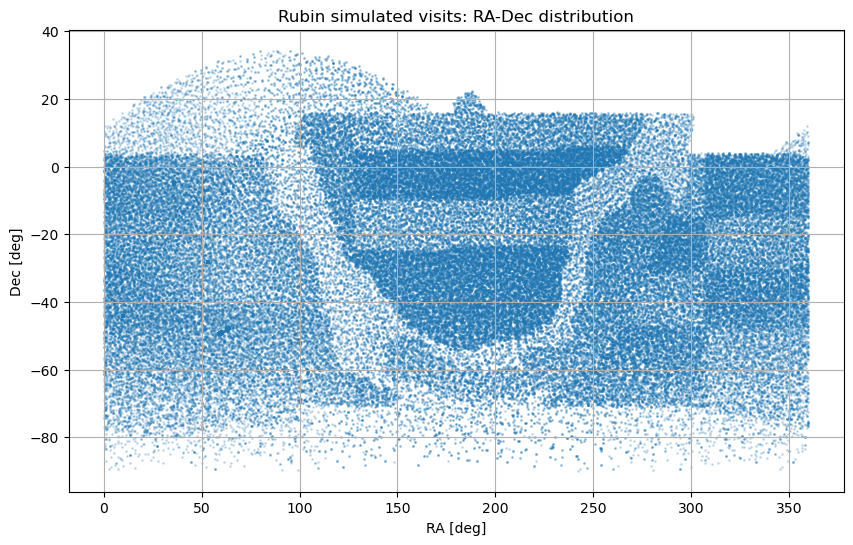

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    ra_dec_catalog["ra_deg"],
    ra_dec_catalog["dec_deg"],
    s=1,
    alpha=0.2,
)

plt.xlabel("RA [deg]")
plt.ylabel("Dec [deg]")

plt.title(
    "Rubin simulated visits: RA-Dec distribution"
)

plt.grid()

plt.show()


## Salvataggio finale

A questo punto nella directory:

```text
rubin_one_year_output/
```

dovresti avere:

```text
rubin_one_year.db
rubin_visits_ra_dec.csv
rubin_visits_ra_dec.parquet
```

Il DataFrame principale utilizzabile per le analisi successive è:

```python
ra_dec_catalog
```

Le colonne più importanti sono:

```text
mjd
datetime_utc
ra_deg
dec_deg
band
```

Il notebook può essere esteso per:

- selezionare regioni specifiche del cielo;
- studiare configurazioni del rotatore;
- trovare visite consecutive;
- calcolare tempi tra pointings;
- produrre mappe HEALPix;
- identificare automaticamente particolari configurazioni strumentali.


In [5]:
import geom_utils as gu
from astropy.coordinates import SkyCoord
import astropy.units as u
from tqdm import tqdm
import pandas as pd
max_dist = 2.025 
min_dist = max_dist-0.03 
limit=7

df = pd.read_csv("./rubin_one_year_output/rubin_visits_ra_dec.csv")
print(df.columns)
ra_arr = df['ra_deg']
dec_arr = df['dec_deg']
st_time_arr = df['datetime_utc']
count = 0
with open("./rubin_one_year_output/one_year_occurrance_horseshoe.txt", "w") as f:
    for i, (ra, dec, st_time) in tqdm(enumerate(zip(ra_arr, dec_arr, st_time_arr)),total=len(ra_arr)):
        center = SkyCoord(ra=ra, dec=dec, unit=(u.deg, u.deg), frame='icrs')
        brightest_stars = gu.find_bright_stars(center, max_dist, sorting='Vmag', mag_filter_dict={"Vmag": "<3"}, limit=limit)
        # if brightest_stars is not None:  print(brightest_stars["Radial_Distance"][0])
        if brightest_stars is not None and any(star > min_dist for star in brightest_stars["Radial_Distance"]):            
            f.write(f" {i}, ")
            count += 1
        if count>1 and count % 25 == 0: print(f"partial occurrences: {count}")


Index(['mjd', 'datetime_utc', 'date_utc', 'year', 'month', 'day', 'hour_utc',
       'ra_rad', 'dec_rad', 'ra_deg', 'dec_deg', 'band', 'filter', 'alt', 'az',
       'airmass', 'rotSkyPos', 'rotTelPos', 'exptime', 'scheduler_note'],
      dtype='object')


  0%|          | 274/196377 [00:00<09:06, 359.10it/s]

  1%|          | 1081/196377 [07:34<22:49:31,  2.38it/s]


KeyboardInterrupt: 

In [3]:
from astropy.coordinates import SkyCoord
from astropy.table import Table
import astropy.units as u
from pathlib import Path
KNOWN_OBJECTS_FITS = Path("./rubin_one_year_output/ybsc_v5.fits")
KNOWN_OBJECTS_CSV = Path("ybsc_v5_known_objects.csv")

# if not KNOWN_OBJECTS_FITS.exists():
#     raise FileNotFoundError(f"File YBSC non trovato: {KNOWN_OBJECTS_FITS.resolve()}")


table = Table.read(KNOWN_OBJECTS_FITS)
from astropy.coordinates import FK4, SkyCoord
from astropy.time import Time

ra_hms_columns = ["RAh1900", "RAm1900", "RAs1900"]
dec_dms_columns = ["DEd1900", "DEm1900", "DEs1900"]

required_columns = ra_hms_columns + dec_dms_columns
missing_columns = [
    column for column in required_columns
    if column not in table.colnames
]

if missing_columns:
    raise ValueError(
        f"Colonne HMS/DMS mancanti in {KNOWN_OBJECTS_FITS}: "
        f"{missing_columns}. Colonne disponibili: {table.colnames}"
    )

ra_h = np.asarray(table["RAh1900"], dtype=float)
ra_m = np.asarray(table["RAm1900"], dtype=float)
ra_s = np.asarray(table["RAs1900"], dtype=float)

dec_d = np.asarray(table["DEd1900"], dtype=float)
dec_m = np.asarray(table["DEm1900"], dtype=float)
dec_s = np.asarray(table["DEs1900"], dtype=float)

# Il segno della declinazione si applica a gradi, primi e secondi.
# np.signbit gestisce anche il caso particolare di -0 gradi.
dec_sign = np.where(np.signbit(dec_d), -1.0, 1.0)

ra_deg = 15.0 * (ra_h + ra_m / 60.0 + ra_s / 3600.0)
dec_deg = dec_sign * (
    np.abs(dec_d) + np.abs(dec_m) / 60.0 + np.abs(dec_s) / 3600.0
)

valid = (
    np.isfinite(ra_deg)
    & np.isfinite(dec_deg)
    & (ra_deg >= 0.0)
    & (ra_deg < 360.0)
    & (np.abs(dec_deg) <= 90.0)
)

if not valid.all():
    print(f"Rimosse {(~valid).sum()} righe con coordinate non valide.")
    ra_deg = ra_deg[valid]
    dec_deg = dec_deg[valid]

# Le colonne *1900 sono in sistema FK4, equinozio B1900.
coords = SkyCoord(
    ra=ra_deg * u.deg,
    dec=dec_deg * u.deg,
    frame=FK4(equinox=Time("B1900")),
).icrs

ra_values = table[ra_col]
dec_values = table[dec_col]

ra_arr = np.asarray(ra_values)
dec_arr = np.asarray(dec_values)

if np.issubdtype(ra_arr.dtype, np.character) or np.issubdtype(dec_arr.dtype, np.character):
    coords = SkyCoord(ra=ra_values, dec=dec_values, frame="icrs")
else:
    coords = SkyCoord(
        ra=ra_arr * u.deg,
        dec=dec_arr * u.deg,
        frame="icrs",
    )

known_objects_df = pd.DataFrame({
    "ra_deg": coords.ra.deg,
    "dec_deg": coords.dec.deg,
})

known_objects_df.to_csv(KNOWN_OBJECTS_CSV, index=False)

print(f"Catalogo YBSC importato da {KNOWN_OBJECTS_FITS.name}")
print(f"Salvato in: {KNOWN_OBJECTS_CSV.resolve()}")
print(f"Oggetti noti: {len(known_objects_df)}")

# Anello problematico rispetto al centro del pointing.
RING_INNER_DEG = 1.995
RING_OUTER_DEG = 2.025

# Spostamento applicato al centro, radialmente lontano dall'oggetto.
POINTING_OFFSET_DEG = 0.05

known_objects = pd.read_csv(KNOWN_OBJECTS_CSV)

if not {"ra_deg", "dec_deg"}.issubset(known_objects.columns):
    raise ValueError("known_objects.csv deve contenere ra_deg e dec_deg.")

objects = SkyCoord(
    ra=known_objects["ra_deg"].to_numpy() * u.deg,
    dec=known_objects["dec_deg"].to_numpy() * u.deg,
    frame="icrs",
)

nominal_pointings = SkyCoord(
    ra=catalog["ra_deg"].to_numpy() * u.deg,
    dec=catalog["dec_deg"].to_numpy() * u.deg,
    frame="icrs",
)

# Oggetto noto più vicino per ogni visita.
nearest_index, nearest_separation, _ = nominal_pointings.match_to_catalog_sky(objects)

compromised = (
    (nearest_separation.deg >= RING_INNER_DEG)
    & (nearest_separation.deg <= RING_OUTER_DEG)
)

# Direzione dall'oggetto al centro nominale: l'offset allontana il centro dall'oggetto.
nearest_objects = objects[nearest_index]
away_position_angle = nearest_objects.position_angle(nominal_pointings)

shifted_pointings = nominal_pointings.directional_offset_by(
    away_position_angle,
    POINTING_OFFSET_DEG * u.deg,
)

shifted_catalog = catalog.copy()

# Mantiene traccia sia delle coordinate nominali sia di quelle corrette.
shifted_catalog["ra_deg_nominal"] = catalog["ra_deg"]
shifted_catalog["dec_deg_nominal"] = catalog["dec_deg"]
shifted_catalog["nearest_object_distance_deg"] = nearest_separation.deg
shifted_catalog["pointing_was_shifted"] = compromised
shifted_catalog["applied_offset_deg"] = np.where(
    compromised,
    POINTING_OFFSET_DEG,
    0.0,
)

# Applica il nuovo pointing solo alle visite compromesse.
shifted_catalog.loc[compromised, "ra_deg"] = shifted_pointings.ra.deg[compromised]
shifted_catalog.loc[compromised, "dec_deg"] = shifted_pointings.dec.deg[compromised]
shifted_catalog["ra_rad"] = np.radians(shifted_catalog["ra_deg"])
shifted_catalog["dec_rad"] = np.radians(shifted_catalog["dec_deg"])

print(f"Visite totali: {len(shifted_catalog)}")
print(f"Visite nell'anello: {compromised.sum()}")
print(f"Offset applicato: {POINTING_OFFSET_DEG} deg")

Rimosse 14 righe con coordinate non valide.


NameError: name 'ra_col' is not defined